# FPS Influence on People-Count Accuracy

## Introduction

**Goal.** Quantify how two timing parameters of the PG2 people-counting pipeline
affect count accuracy in a controlled room:

- **Detection reporting period** — how often the sensor reports detections (its
  effective frame rate / fps).
- **Count aggregation period** — how often the gateway aggregates detections
  into a reported room count.

**Subjects.**
- *Detection stream* from a single ceiling sensor (`6000703-1221-012345-4040`),
  parsed from the gateway log.
- *Aggregation pipeline* — the gateway's count logic (`PG2_GW` →
  `sendAgreggateCount`, smoothing on), driven through the `algo_system_emulator`
  port so no logic is reimplemented.
- *Ground truth* — the true number of people in the room over time.


## 1. Input detections

The sensor reports a telemetry frame roughly every **10 s** (≈0.1 fps); each
frame carries zero or more person detections. Over the ~1 h 47 m session the
input consists of:

- **594 frames**, **452 raw detections** total;
- native reporting period **≈10.8 s** (min 10 s, max 17 s — mild jitter);
- ground truth changes as a step function: **0 → 1 → 2 people** during the run.

Taking each frame's raw detection count directly as the room count (no
aggregation) already matches ground truth **86.4 %** of the time — the baseline
we aim to improve through aggregation, and the ceiling that lower fps erodes.


In [1]:
import pandas as pd
from IPython.display import display

ART = "artifacts"
det = pd.read_csv(f"{ART}/detections.csv")
ts = pd.to_datetime(det["timestamp"], format="%b %d %H:%M:%S")
gap = ts.diff().dt.total_seconds().dropna()

summary = pd.Series({
    "frames": len(det),
    "total detections": int(det["num_detections"].sum()),
    "session span": f"{ts.min():%H:%M:%S} – {ts.max():%H:%M:%S}",
    "reporting period (mean)": f"{gap.mean():.1f} s",
    "reporting period (min–max)": f"{gap.min():.0f}–{gap.max():.0f} s",
    "per-frame count correct vs GT": f"{(det['num_detections'] == det['gt_num_person']).mean()*100:.1f} %",
}, name="value")
display(summary.to_frame())

,value
frames,594
total detections,452
session span,05:19:25 – 07:06:05
reporting period (mean),10.8 s
reporting period (min–max),10–17 s
per-frame count correct vs GT,86.4 %


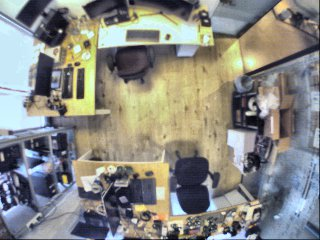

In [2]:
from IPython.display import Image
# Controlled environment as seen by the sensor.
Image(filename="ControlledENV/6000703-1221-012345-4040.jpg", width=420)

## 2. Experiment & methodology

**Design.** A 4×4 grid over the two periods, evaluated against ground truth:

- **Detection period** (input fps): **10, 20, 30, 60 s**. The native ~10 s stream
  is *row-decimated* — keep every *k*-th frame (`k = period/10`) — which
  preserves the real inter-report timing while simulating a slower sensor.
- **Count period** (output cadence): **30, 60, 90, 120 s**. The aggregator
  (median-3 + EMA-0.25 smoothing, whole-room AOI, matching the deployed gateway)
  emits a count at each period tick.

**Metric — exact-match accuracy.** Each configuration produces one reported
count per period tick. Every tick is matched to the ground-truth count in effect
at that time, and accuracy is the share of ticks whose reported count equals
ground truth exactly:

$$\text{Accuracy} = \frac{1}{N}\sum_{i=1}^{N}\mathbf{1}\!\left[\hat{y}_i = y_i\right]\times 100\%$$

where $N$ is the number of report ticks, $\hat{y}_i$ the reported count at tick
$i$, $y_i$ the ground-truth count at tick $i$, and $\mathbf{1}[\cdot]$ the
indicator (1 if the counts match, 0 otherwise).

*Toy example.* Ground truth $y = [0,\,1,\,2,\,2,\,1]$ and reported
$\hat{y} = [0,\,1,\,1,\,2,\,1]$ over $N=5$ ticks. Ticks 1, 2, 4, 5 match; tick 3
does not ($1 \neq 2$), so $\mathbf{1}[\cdot] = [1,1,0,1,1]$ and
$\text{Accuracy} = \tfrac{4}{5}\times 100\% = 80\%$.


In [3]:
res = pd.read_csv(f"{ART}/sweep/eval_results.csv")

print("Exact-match accuracy (%) — higher is better")
display(res.pivot(index="detection_period", columns="count_period", values="accuracy")
           .rename_axis("det ↓ / count →").style.format("{:.1f}")
           .background_gradient(cmap="RdYlGn", vmin=60, vmax=100))

Exact-match accuracy (%) — higher is better


count_period,30,60,90,120
det ↓ / count →,,,,
10,90.2,89.7,95.8,96.3
20,87.4,88.8,90.3,92.6
30,86.0,91.6,93.1,94.4
60,65.4,85.0,86.1,92.6


## 3. Conclusions

- **Lower detection fps degrades accuracy**, but only mildly until it becomes
  sparse. At a fixed 60 s count period, accuracy falls from ~90 % (10 s) to
  85 % (60 s); the collapse appears only in the starved corner **60 s detection
  / 30 s count → 65 %**, where a 30 s window rarely contains a fresh detection.
- **A longer count period compensates for low fps.** Reading down any column, a
  bigger aggregation window recovers most of the loss: even the 60 s sensor
  reaches **92.6 %** at a 120 s count period. Smoothing over more time fills the
  gaps a slow sensor leaves.
- **Best trade-off:** dense input with a moderately long window — **10 s / 120 s
  → 96.3 %**. For a constrained low-fps sensor, pair it with the **longest
  affordable count period**.
- **Caveat:** longer count periods are scored on fewer, coarser ticks (214 at
  30 s → 54 at 120 s), so comparisons *down a column* (fps effect at fixed
  cadence) are cleaner than *across a row*.
